# Hackathon: explore a BDF recording

Use this notebook as an example to inspect a recording, view EEG, select a time interval or marker, and estimate its power spectral density (PSD). It uses MNE, NumPy, pandas and Matplotlib.

Run cells in order. Change the path and settings to explore your own file. Times below are seconds **relative to the start of the loaded BDF**. This is exploratory analysis, not a finished preprocessing pipeline.

## 1. Environment

Create the environment as described in the repository README and choose it as your Jupyter kernel. Restart the kernel after installing. pyEDFlib reads the original BDF signals, units and sampling rates; MNE provides annotations and EEG spectral analysis. The static plots below work in ordinary notebooks.

In [1]:
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.integrate import trapezoid

print(f"MNE {mne.__version__}")

MNE 1.11.0


## 2. Choose and load a recording

Set `bdf_path` to a file on your machine. The example is a curated resting-state recording. To discover files under a directory, use `dataset_root.rglob("*.bdf")`.

The reusable [`load_bdf`](bdf_loader.py) function reads annotations, channel metadata and the whole signal table without our internal library. To reuse it, copy the module including its imports, and install its dependencies in your environment. For a submitted job, add those dependencies to the root `requirements.txt`. Loading the full table can require substantial memory for long recordings.

In [2]:
# Start the kernel in the repository root or in starting_notebooks/.
cwd = Path.cwd().resolve()
if (cwd / "starting_notebooks" / "bdf_loader.py").is_file():
    ROOT = cwd
elif cwd.name == "starting_notebooks" and (cwd / "bdf_loader.py").is_file():
    ROOT = cwd.parent
else:
    raise RuntimeError("Start the kernel in the repository root or starting_notebooks/.")
dataset_root = ROOT / "sample" / "CURATED"
bdf_path = dataset_root / "P001/P001_day-1_task-resting-state_multimodal.bdf"
# Alternatively: bdf_path = Path("/path/to/your/recording.bdf")


### Load the recording

The function returns `raw` (MNE metadata and annotations), `data_df` (the full signal table), and `channels` (names, modalities, original units and stored rates). It uses the same-name `.record_map` when present.

If no sidecar is available, it uses the example dataset's EEG names. For another recording, pass an editable list of names as `fallback_eeg`; check the resulting channel table and units. Signals of unknown modality are marked `misc`.

BDF stores signals in fixed-duration data records: each channel has an integer number of samples per record, so channels can have different stored rates. It does not retain the original XDF timestamps for each sample. The `.record_map` can preserve an effective rate and gaze onset offset that help reconstruct a shared timeline.

We use pyEDFlib to read physical signal values in the **BDF header units** shown in `channels`. Channels stored at the master rate go directly into `data_df`. Lower-rate gaze channels are placed on the master timeline using the same sparse policy as our internal BDF adapter: estimated sample positions contain gaze values and the other rows contain `NaN`. During export, leading placeholder samples are written at the gaze rate for an onset delay; on import, their estimated count is removed using `OnsetSeconds` and the effective rate. The remaining gaze values are distributed using evenly spaced indices.

These positions are reconstructed, not the original gaze timestamps. `TotalSamples`, when available in the record map, removes final BDF record padding. Arbitrary missing samples cannot necessarily be recovered. This example follows the adapter's effective-rate calculation; nominal-rate exports can use a different filler count. Work is underway on an approach that interpolates the original XDF streams onto their nominal rates (for example, 1,000 Hz for EEG and 200 Hz for gaze); it is not implemented here.

If a record map is missing or a lower-rate channel is not in the gaze group, its values are left as `NaN` rather than aligned without enough information. Inspect `channels` before using any modality. The full DataFrame is suited to short resting-state recordings; its memory usage grows with duration and channel count.

In [3]:
import sys

# Make the module importable from either supported working directory.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from starting_notebooks.bdf_loader import load_bdf

raw, data_df, channels = load_bdf(bdf_path)
# Without a record map, you can supply your own channel names instead:
# raw, data_df, channels = load_bdf(bdf_path, fallback_eeg=["Fz", "C3", "C4"])

sfreq = float(raw.info["sfreq"])
eeg_channels = channels.loc[channels["mne_type"] == "eeg", "bdf_label"].tolist()
print(f"File: {bdf_path.name}")
print(f"{len(data_df) / sfreq:.2f} s, {sfreq:g} Hz, {len(eeg_channels)} EEG channels")
display(channels)

Channel metadata: P001_day-1_task-resting-state_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.005 s
File: P001_day-1_task-resting-state_multimodal.bdf
95.08 s, 1000 Hz, 64 EEG channels


,bdf_label,header_unit,header_rate_hz,map_name,modality,map_unit,mne_type
0,Fp1,uV,1000.0,Fp1,EEG,uV,eeg
1,Fp2,uV,1000.0,Fp2,EEG,uV,eeg
2,F9,uV,1000.0,F9,EEG,uV,eeg
3,F7,uV,1000.0,F7,EEG,uV,eeg
4,F3,uV,1000.0,F3,EEG,uV,eeg
...,...,...,...,...,...,...,...
78,eyeballcentery_r,mm,166.0,eyeballcentery_right,Oculometry,mm,misc
79,eyeballcenterz_r,mm,166.0,eyeballcenterz_right,Oculometry,mm,misc
80,opticalaxisx_rig,unitless,166.0,opticalaxisx_right,Oculometry,unitless,misc
81,opticalaxisy_rig,unitless,166.0,opticalaxisy_right,Oculometry,unitless,misc


### Inspect the signal table

`data_df` contains the whole recording. Values are in the **BDF header units** listed in `channels`; changing an MNE channel type does not apply the sidecar units or convert the table's samples. The EEG plotting and PSD cells below convert values explicitly.

The function reconstructs the positions of lower-rate gaze samples on the master timeline when the sidecar provides enough information. These positions are estimates, not the original gaze timestamps. Without a mapping, lower-rate signals are left as `NaN` rather than aligned speculatively. The full table is convenient for short recordings; memory usage grows with recording length.

In [4]:
display(data_df.head(12))

,time_s,Fp1,Fp2,F9,F7,F3,Fz,F4,F8,F10,...,opticalaxisx_lef,opticalaxisy_lef,opticalaxisz_lef,pupildiameter_ri,eyeballcenterx_r,eyeballcentery_r,eyeballcenterz_r,opticalaxisx_rig,opticalaxisy_rig,opticalaxisz_rig
0,0.000,201.149796,-6914.829976,-6610.020045,-10987.159835,-10965.389938,881.111794,-3500.879949,-7062.059858,-12049.849611,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.001,213.939893,-6898.439933,-6615.360032,-10994.159900,-10966.369978,887.012539,-3493.619927,-7060.389810,-12042.689726,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.002,201.479766,-6914.110015,-6617.860034,-10998.179931,-10972.559855,880.260278,-3501.819927,-7069.039988,-12056.219569,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.003,231.419943,-6878.419822,-6611.260044,-10986.859847,-10958.119670,892.823085,-3485.679863,-7051.989922,-12024.929733,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.004,251.779842,-6859.249793,-6604.310157,-10975.429925,-10946.879918,900.062895,-3476.239973,-7040.919792,-12007.049718,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.005,272.129938,-6837.219940,-6597.330070,-10964.389613,-10941.059776,907.930555,-3465.609962,-7026.389815,-11992.730026,...,0.116365,0.432057,0.894307,4.020112,31.59375,7.625,-35.40625,-0.077504,0.418801,0.904765
6,0.006,286.579776,-6823.609884,-6589.770117,-10958.479643,-10937.309885,911.851020,-3457.559991,-7012.749841,-11980.479906,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.007,297.179790,-6811.809857,-6584.220199,-10956.139963,-10935.319797,916.031950,-3453.499861,-7005.249985,-11971.379705,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0.008,301.509781,-6807.240017,-6570.350136,-10944.259855,-10923.909776,921.892600,-3447.649959,-6995.059801,-11960.359920,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.009,295.119800,-6814.050050,-6571.490075,-10946.909612,-10924.139676,916.482760,-3449.629881,-6997.819943,-11962.109581,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Inspect markers

BDF annotations are shown below. Onsets are converted to recording-relative seconds. Some files instead store triggers in a status/stim channel: inspect the channel table and use `mne.find_events` after confirming the appropriate channel and encoding. An empty table means no BDF annotations were found, not necessarily that the experiment had no events.

Curated metadata JSON onsets can use a different, full-session time origin. Do not use them directly as BDF-relative timestamps: see `dataset_export` in the sidecar and subtract the matching segment's `metadata_time_origin_s`.

In [5]:
annotations = raw.annotations
events = pd.DataFrame(
    {
        "onset_s": annotations.onset - raw.first_time,
        "duration_s": annotations.duration,
        "description": annotations.description,
    }
)
display(events)

,onset_s,duration_s,description
0,0.000,0.0,10002
1,30.001,0.0,10003
2,35.078,0.0,10004
3,95.079,0.0,10005


## 4. Select a segment

Choose `"time"` or `"marker"`. Marker mode uses a marker description and occurrence (0 = first), followed by a fixed duration; it does not infer an end marker. Make sure the interval is inside the recording. Selection uses a half-open interval `[start, stop)`, in seconds from the start of the loaded BDF.

In [6]:
def select_segment(
    selection_type: Literal["time", "marker"],
    start_s: float | None = None,
    marker_description: str = "10004",
    marker_occurrence: int = 0,
    duration_s: float = 10,
) -> tuple[int, int, int]:
    if selection_type == "marker":
        if start_s:
            print(
                "WARNING: Selection type is 'marker'. Your 'start_s' value will not be used."
            )
        matches = events.loc[
            events["description"] == str(marker_description), "onset_s"
        ]
        if marker_occurrence < 0 or marker_occurrence >= len(matches):
            raise ValueError(
                f"Marker {marker_description!r} occurrence {marker_occurrence} not found; inspect events above."
            )
        start_s = float(matches.iloc[marker_occurrence])
    elif selection_type != "time":
        raise ValueError("selection must be 'time' or 'marker'")

    if start_s is None:
        raise ValueError("Provide start_s for time selection.")
    start_sample = round(start_s * sfreq)
    n_samples = round(duration_s * sfreq)
    stop_sample = start_sample + n_samples
    if start_s < 0 or duration_s <= 0 or n_samples < 2 or stop_sample > len(data_df):
        raise ValueError(
            "Segment must contain at least two samples and fit inside the recording."
        )
    print(
        f"Selected samples {start_sample}:{stop_sample} ({start_sample / sfreq:.3f}–{stop_sample / sfreq:.3f} s)"
    )

    return start_sample, stop_sample, n_samples


start_sample, stop_sample, n_samples = select_segment(
    selection_type="marker", marker_description="10002", duration_s=30
)

Selected samples 0:30000 (0.000–30.000 s)


## 5. Plot the signal modalities

Each trace has its own axis and unit. We show four EEG electrodes and the other modalities, including gaze and pupil diameter. For a shorter overview, the eyeball-center and optical-axis channels are omitted from this plot; they remain available in `data_df`. Change `eeg_channels[:4]` to `eeg_channels` to plot all EEG electrodes. Dots show lower-rate samples without connecting or inventing values. Times are relative to the BDF start.

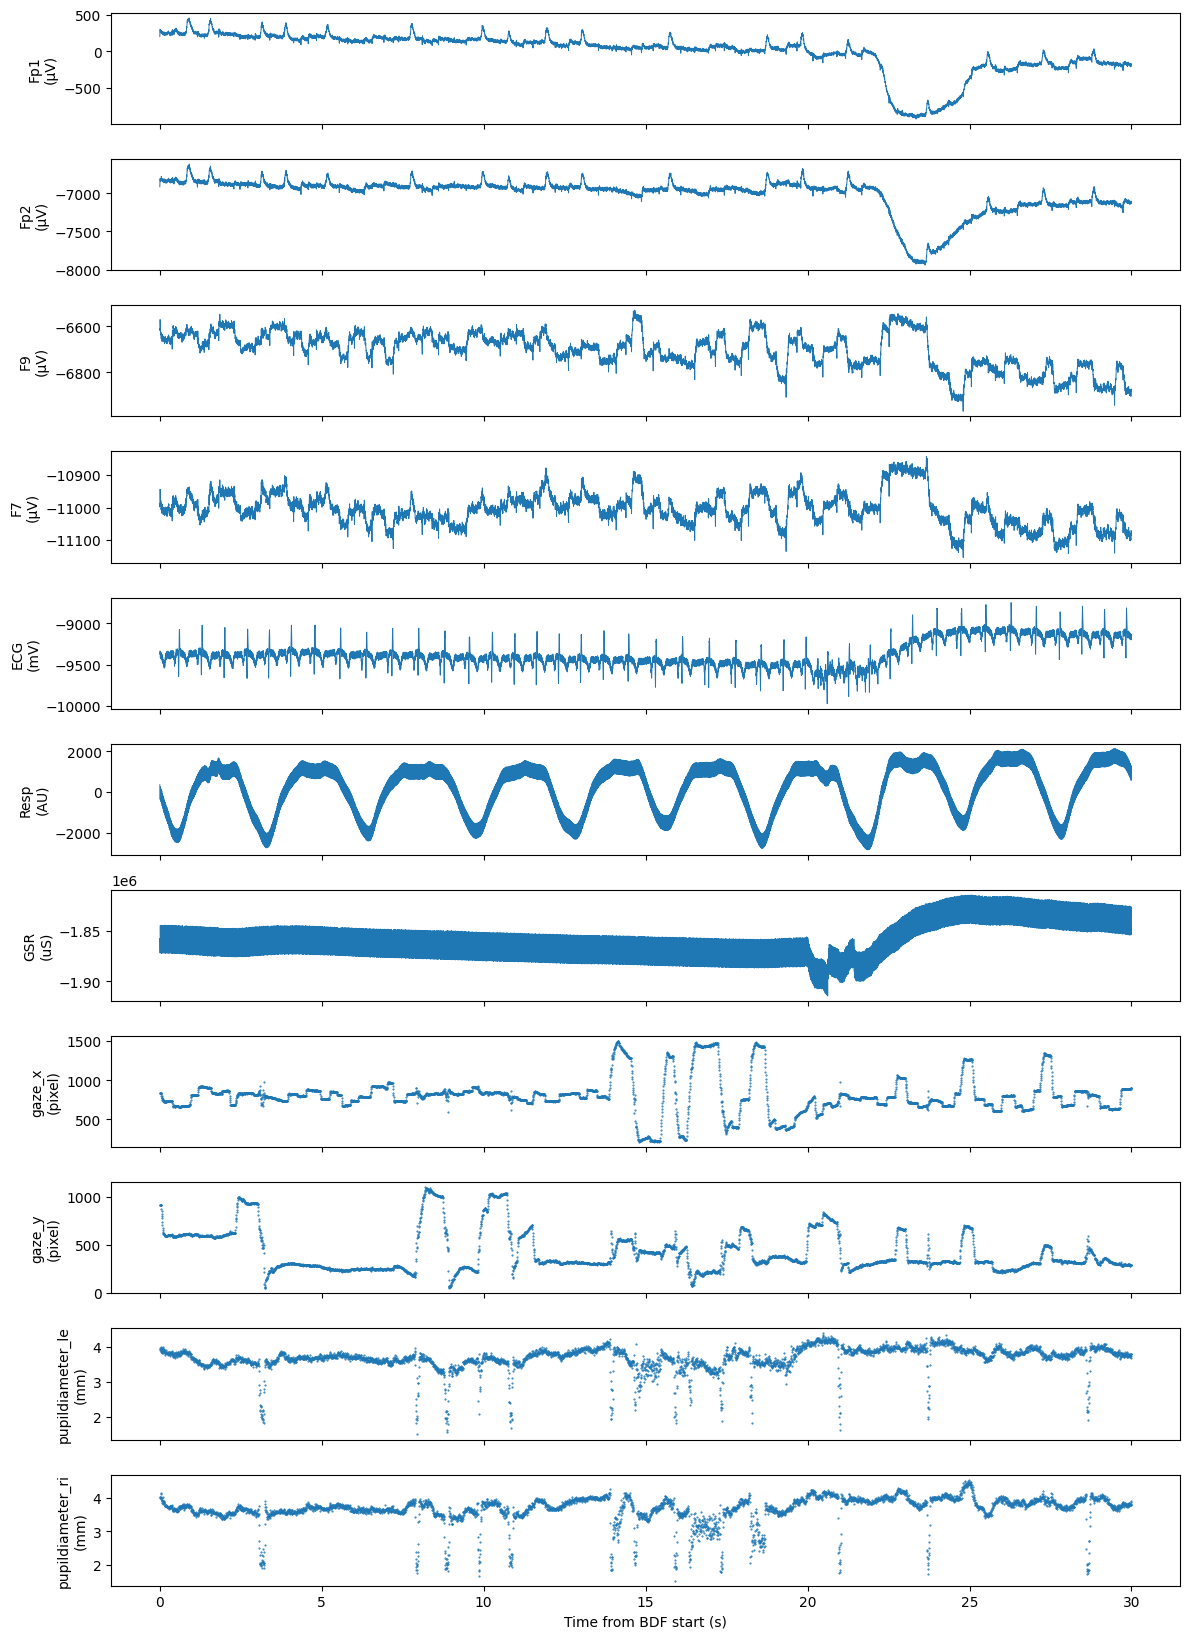

In [7]:
from typing import cast

from matplotlib.axes import Axes

segment_df = data_df.iloc[start_sample:stop_sample].copy()
# Convert from the BDF header unit to microvolts for display.
unit_to_volts = {"V": 1.0, "mV": 1e-3, "uV": 1e-6, "µV": 1e-6, "μV": 1e-6, "nV": 1e-9}
header_unit_by_channel = channels.set_index("bdf_label")["header_unit"].to_dict()
other_channels = channels.loc[channels["mne_type"] != "eeg", "bdf_label"].tolist()
# Skip the detailed 3D eye-model channels in this overview.
other_channels: list[str] = [ch for ch in other_channels
                  if not ch.lower().startswith(("eyeballcenter", "opticalaxis"))]
plot_channels = eeg_channels[:4] + other_channels

fig, axes = plt.subplots(
    len(plot_channels),
    1,
    sharex=True,
    figsize=(12, 1.5 * len(plot_channels)),
    squeeze=False,
)
for item, ch in zip(axes[:, 0], plot_channels, strict=True):
    values = segment_df[ch].to_numpy()
    unit = header_unit_by_channel[ch]
    if ch in eeg_channels:
            values = values * unit_to_volts[unit] * 1e6
            unit = "µV"
    valid = np.isfinite(values)
    ax = cast(Axes, item)
    if valid.all():
        ax.plot(segment_df["time_s"], values, linewidth=0.7)
    elif valid.any():
        ax.plot(segment_df["time_s"][valid], values[valid], ".", markersize=1)
    else:
        ax.text(0.5, 0.5, "No aligned samples available", transform=ax.transAxes)
    ax.set_ylabel(f"{ch}\n({unit})")
cast(Axes, axes[-1, 0]).set_xlabel("Time from BDF start (s)")
fig.tight_layout()
plt.show()

## 6. Estimate EEG power with Welch's method

Convert the selected EEG data from its BDF header units to volts, create an MNE object, and calculate PSD. Power is shown in µV²/Hz. Welch's window length controls frequency resolution, and a short segment gives a less stable estimate. The input is not filtered or artifact-cleaned; eye movements, muscle activity, poor electrodes and line noise can dominate the result.

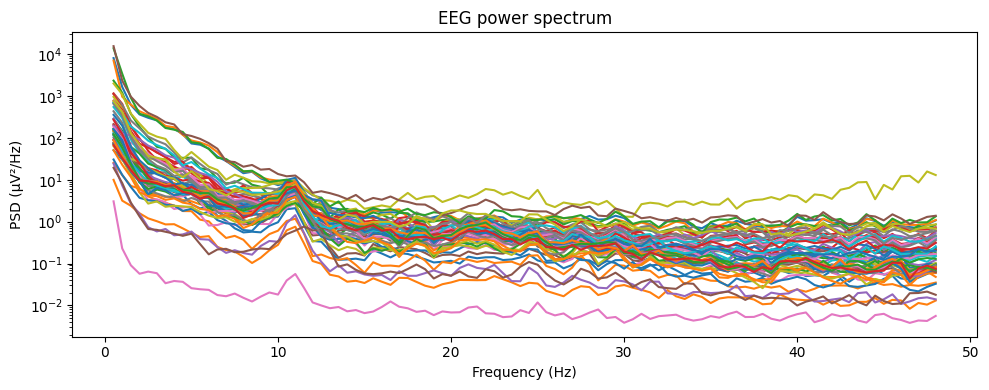

In [8]:
# MNE expects EEG values in volts, regardless of the BDF header units.
eeg_volts = np.vstack(
    [
        segment_df[ch].to_numpy() * unit_to_volts[header_unit_by_channel[ch]]
        for ch in eeg_channels
    ]
)
eeg_info = mne.create_info(ch_names=eeg_channels, sfreq=sfreq, ch_types="eeg")
eeg_segment = mne.io.RawArray(eeg_volts, eeg_info, verbose="ERROR")
window_samples = min(round(2 * sfreq), eeg_segment.n_times)
max_freq = min(48, sfreq / 2)
if window_samples < 2 or max_freq <= 1:
    raise ValueError("Sampling rate or segment is too short for this PSD example.")
spectrum = eeg_segment.compute_psd(
    method="welch",
    fmin=0.5,
    fmax=max_freq,
    n_fft=window_samples,
    n_per_seg=window_samples,
    n_overlap=window_samples // 2,
    verbose=False,
)
psd, freqs = spectrum.get_data(return_freqs=True)  # V²/Hz, channels × frequencies
psd_uv = psd * 1e12  # µV²/Hz
fig, ax = plt.subplots(figsize=(10, 4))
for ch in range(len(psd)):
    ax.plot(freqs, psd_uv[ch])
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (µV²/Hz)", title="EEG power spectrum")
ax.set_yscale("log")
fig.tight_layout()
plt.show()

### Example feature: alpha-band power

Integrate each channel's PSD over 8–12 Hz to obtain absolute power in µV². This is a simple example feature, not a clinical measure. Compare equivalent segment lengths, channels and preprocessing across recordings.

In [9]:
alpha = (freqs >= 8) & (freqs <= 12)
if alpha.sum() < 2:
    raise ValueError(
        "PSD has too few frequency bins in the alpha band; use a longer segment/window or higher sampling rate."
    )
alpha_power = pd.DataFrame(
    {
        "channel": eeg_segment.ch_names,
        "alpha_power_uV2": trapezoid(psd_uv[:, alpha], x=freqs[alpha], axis=1),
    }
).sort_values("alpha_power_uV2", ascending=False)
display(alpha_power.head(10))

,channel,alpha_power_uV2
35,AF8,59.009792
32,AF7,39.213133
1,Fp2,37.081788
0,Fp1,34.438020
8,F10,31.834276
18,T10,30.042128
2,F9,25.665352
7,F8,23.700366
17,T8,22.683508
30,O1,22.469032


## 7. Interactive MNE signal browser (optional)

Run this cell on a computer with a graphical desktop. It opens a separate Qt window; scroll through channels and time, and use MNE's controls to zoom. In VS Code the window may open behind the editor. PySide6 is included in the notebook environment. If the window cannot open, skip this optional cell; the static plots above do not need it.

The browser shows the selected segment: ECG, respiration, skin conductance and pupil channels first, followed by EEG. EEG and ECG are converted to volts for MNE. Pupil samples are interpolated onto the EEG time grid **for display only**, with edge values repeated; channels with gaps longer than 0.5 s are omitted. The reconstructed gaze times are estimates, and the interpolated values are not suitable as original measurements. The static plot above shows the available samples without interpolation.

In [11]:
%matplotlib qt

# MNE's browser expects one sampling rate, so prepare the selected segment.
extras = channels[(channels["mne_type"].isin(["ecg", "resp"])) |
                  (channels["modality"].str.lower() == "gsr") |
                  (channels["bdf_label"].str.lower().str.contains("pupil"))]
channel_info = channels.set_index("bdf_label")
viewer_data, viewer_names, viewer_types = [], [], []
for ch in extras["bdf_label"].tolist() + eeg_channels:
    row = channel_info.loc[ch]
    values = segment_df[ch].to_numpy(copy=True)
    valid = np.isfinite(values)
    kind, unit = row["mne_type"], row["header_unit"]
    if "pupil" in ch.lower():
        indices = np.flatnonzero(valid)
        if len(indices) < 2 or np.diff(indices).max() > 0.5 * sfreq or unit not in ("mm", "m"):
            print(f"Skipping {ch}: insufficient or widely spaced pupil samples")
            continue
        values = np.interp(np.arange(len(values)), indices, values[valid])
        values *= 1e-3 if unit == "mm" else 1  # MNE expects pupil diameter in metres.
        kind = "pupil"
    elif not valid.all():
        print(f"Skipping {ch}: missing samples")
        continue
    elif kind in ("eeg", "ecg"):
        values *= unit_to_volts[unit]  # MNE expects volts.
    viewer_data.append(values)
    viewer_names.append(ch if kind == "eeg" else f"{ch} [{unit}]")
    viewer_types.append(kind)

viewer_info = mne.create_info(viewer_names, sfreq, viewer_types)
viewer_raw = mne.io.RawArray(np.array(viewer_data), viewer_info,
                             first_samp=start_sample, verbose="ERROR")
with mne.viz.use_browser_backend("matplotlib"):
    viewer = viewer_raw.plot(duration=min(10, len(segment_df) / sfreq),
                             n_channels=min(20, len(viewer_names)), scalings="auto",
                             highpass=1,
                             group_by="original", show_first_samp=True, block=False)
# Optional: return to inline figures in later notebook cells with %matplotlib inline.

Setting up high-pass filter at 1 Hz

IIR filter parameters
---------------------
Butterworth highpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 8 (effective, after forward-backward)
- Cutoff at 1.00 Hz: -6.02 dB



## Ideas to explore

- Compare alpha power between two marker-defined or timestamp-defined intervals, such as eyes open and eyes closed, after checking what each marker means.
- Plot a spectrogram to see how power changes over time, or compare PSDs across electrodes.
- Inspect noisy channels and artifacts, then investigate filtering and rereferencing on a copy of the data before comparing results.
- Join event information or experimental labels to segment-level features. Confirm time origins and whether events overlap the segment before joining.